(14366, 64)
(2000, 64)
churn
0    7183
1    7183
Name: count, dtype: int64
Accuracy : 0.6865
Precision: 0.1903
Recall   : 0.6373
F1 Score : 0.2931
ROC AUC  : 0.7251

Classification Report

              precision    recall  f1-score   support

           0       0.94      0.69      0.80      1796
           1       0.19      0.64      0.29       204

    accuracy                           0.69      2000
   macro avg       0.57      0.66      0.55      2000
weighted avg       0.87      0.69      0.75      2000



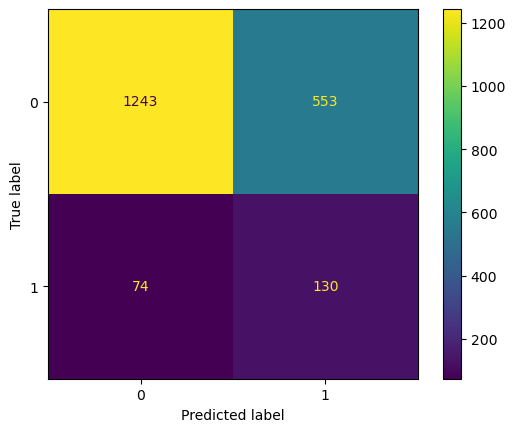

Accuracy : 0.8195
Precision: 0.2103
Recall   : 0.2794
F1 Score : 0.24
ROC AUC  : 0.5801

Classification Report

              precision    recall  f1-score   support

           0       0.91      0.88      0.90      1796
           1       0.21      0.28      0.24       204

    accuracy                           0.82      2000
   macro avg       0.56      0.58      0.57      2000
weighted avg       0.84      0.82      0.83      2000



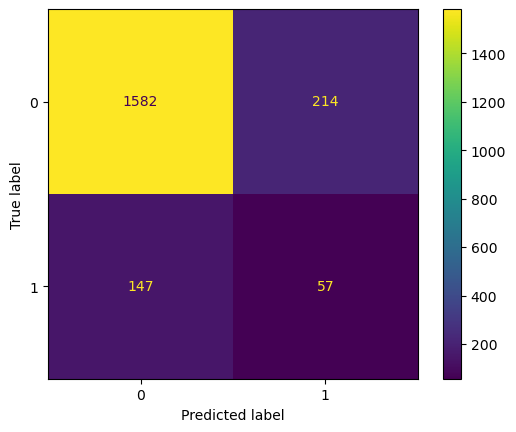

Accuracy : 0.892
Precision: 0.3125
Recall   : 0.049
F1 Score : 0.0847
ROC AUC  : 0.7808

Classification Report

              precision    recall  f1-score   support

           0       0.90      0.99      0.94      1796
           1       0.31      0.05      0.08       204

    accuracy                           0.89      2000
   macro avg       0.61      0.52      0.51      2000
weighted avg       0.84      0.89      0.86      2000



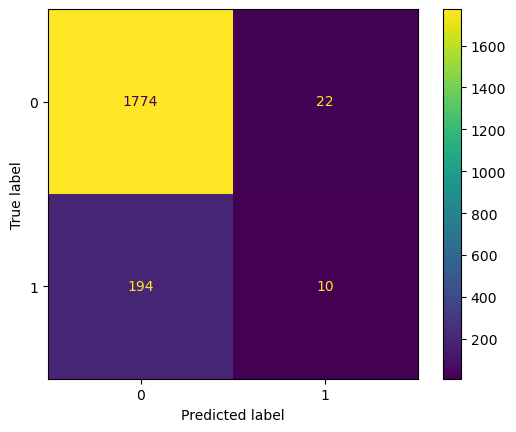

Accuracy : 0.883
Precision: 0.2727
Recall   : 0.0882
F1 Score : 0.1333
ROC AUC  : 0.7632

Classification Report

              precision    recall  f1-score   support

           0       0.90      0.97      0.94      1796
           1       0.27      0.09      0.13       204

    accuracy                           0.88      2000
   macro avg       0.59      0.53      0.54      2000
weighted avg       0.84      0.88      0.86      2000



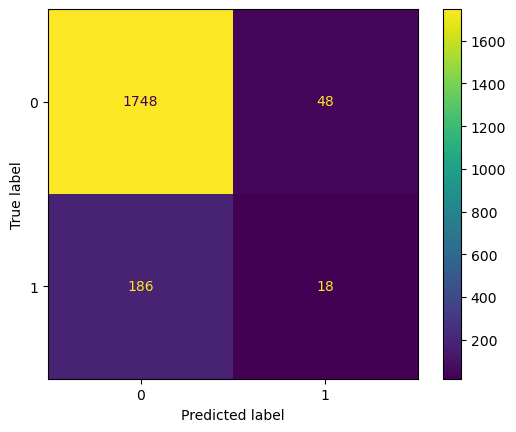

                      Feature  Importance
13                 csat_score    0.136635
62  survey_response_satisfied    0.082882
10           payment_failures    0.076096
57       discount_applied_yes    0.071824
33                gender_male    0.055385


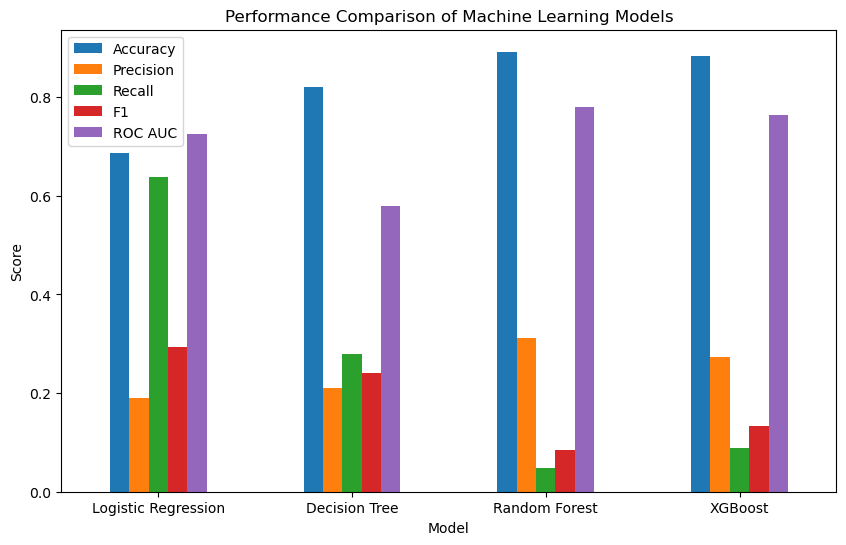

<Figure size 800x600 with 0 Axes>

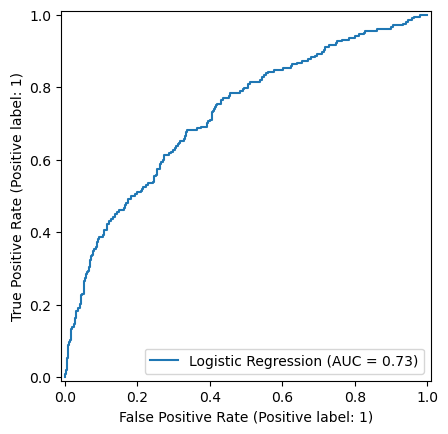

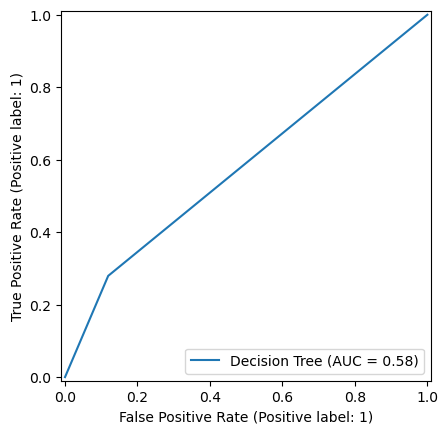

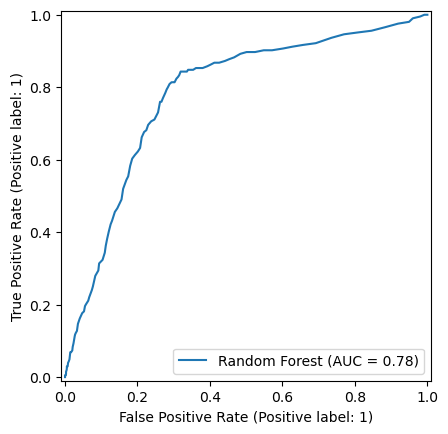

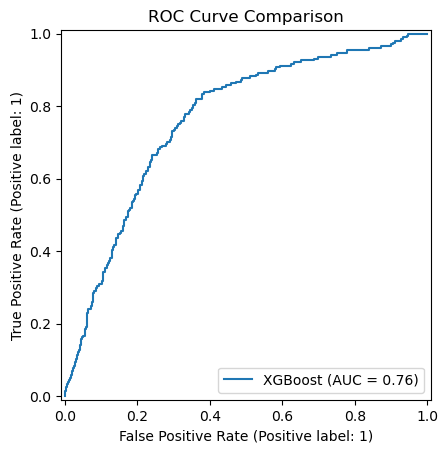

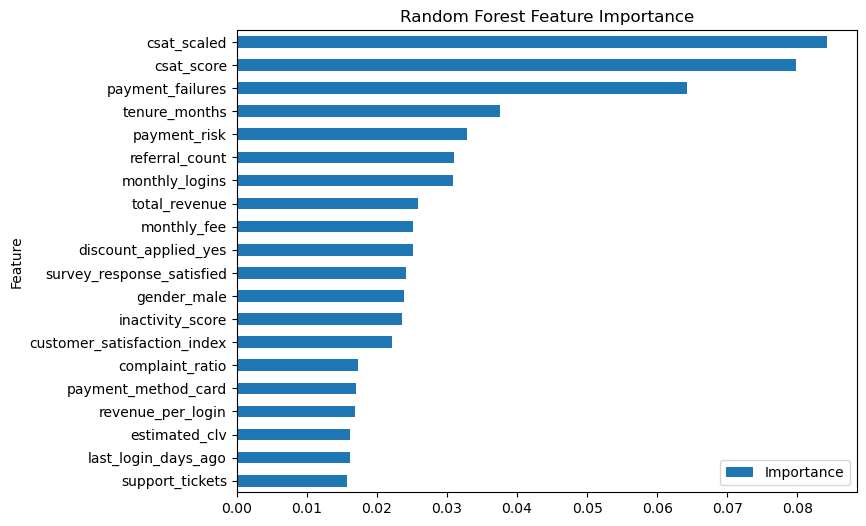

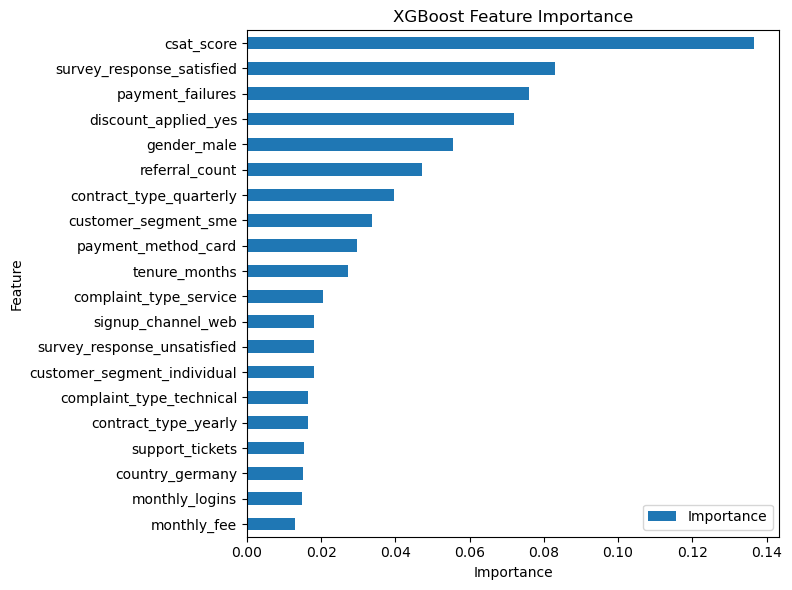

In [2]:
#Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


#Load the prepared dataset

X_train = pd.read_csv("X_train_final.csv")

X_test = pd.read_csv("X_test_final.csv")

y_train = pd.read_csv("y_train_final.csv").squeeze()

y_test = pd.read_csv("y_test_final.csv").squeeze()



#Check the Dataset loaded correctly

print(X_train.shape)
print(X_test.shape)

print(y_train.value_counts())


#Evaluation function 

def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:,1]

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(y_test, y_pred)

    recall = recall_score(y_test, y_pred)

    f1 = f1_score(y_test, y_pred)

    roc = roc_auc_score(y_test, y_prob)

    print("Accuracy :", round(accuracy,4))
    print("Precision:", round(precision,4))
    print("Recall   :", round(recall,4))
    print("F1 Score :", round(f1,4))
    print("ROC AUC  :", round(roc,4))

    print("\nClassification Report\n")

    print(classification_report(y_test,y_pred))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred
    )

    plt.show()

    return accuracy,precision,recall,f1,roc


#Logistic Regression 

lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr.fit(
    X_train,
    y_train
)

lr_results = evaluate_model(
    lr,
    X_test,
    y_test
)

#Decision Tree

dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(
    X_train,
    y_train
)

dt_results = evaluate_model(
    dt,
    X_test,
    y_test
)

#Random Forest

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(
    X_train,
    y_train
)

rf_results = evaluate_model(
    rf,
    X_test,
    y_test
)

#XGBoost

xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb.fit(
    X_train,
    y_train
)

xgb_results = evaluate_model(
    xgb,
    X_test,
    y_test
)

# Create XGBoost Feature Importance DataFrame

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print(xgb_importance.head())


#Comparing all models 

results = pd.DataFrame({

    "Model":[

        "Logistic Regression",

        "Decision Tree",

        "Random Forest",

        "XGBoost"

    ],

    "Accuracy":[

        lr_results[0],

        dt_results[0],

        rf_results[0],

        xgb_results[0]

    ],

    "Precision":[

        lr_results[1],

        dt_results[1],

        rf_results[1],

        xgb_results[1]

    ],

    "Recall":[

        lr_results[2],

        dt_results[2],

        rf_results[2],

        xgb_results[2]

    ],

    "F1":[

        lr_results[3],

        dt_results[3],

        rf_results[3],

        xgb_results[3]

    ],

    "ROC AUC":[

        lr_results[4],

        dt_results[4],

        rf_results[4],

        xgb_results[4]

    ]

})

results

#visualization of model comparisons 

results.plot(
    x="Model",
    y=["Accuracy","Precision","Recall","F1","ROC AUC"],
    kind="bar",
    figsize=(10,6)
)

plt.ylabel("Score")

plt.title("Performance Comparison of Machine Learning Models")

plt.xticks(rotation=0)

plt.show()


#Compare ROC Curves

plt.figure(figsize=(8,6))

RocCurveDisplay.from_estimator(lr, X_test, y_test, name="Logistic Regression")
RocCurveDisplay.from_estimator(dt, X_test, y_test, name="Decision Tree")
RocCurveDisplay.from_estimator(rf, X_test, y_test, name="Random Forest")
RocCurveDisplay.from_estimator(xgb, X_test, y_test, name="XGBoost")

plt.title("ROC Curve Comparison")
plt.show()


#Feature Importance

#Random Forest
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

rf_importance.head(20)


#Ploting the Feature Importance - Random Forest
rf_importance.head(20).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(8,6)
)

plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.show()

# Plot Top 20 XGBoost Feature Importance

xgb_importance.head(20).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(8,6)
)

plt.gca().invert_yaxis()

plt.title("XGBoost Feature Importance")

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.show()


#Save the models

import joblib

joblib.dump(lr,"LogisticRegression.pkl")

joblib.dump(dt,"DecisionTree.pkl")

joblib.dump(rf,"RandomForest.pkl")

joblib.dump(xgb,"XGBoost.pkl")

#Save the model performance results to CSV
results.to_csv("Model_Performance.csv", index=False)
    